# Final End-to-End Pipeline Validation

This notebook evaluates the reconstructed cortical trajectory analysis pipeline against the legacy Brain Column pipeline using two validation subjects:

- **D0007**
- **S00775**

Both subjects are evaluated through the complete downstream analysis chain:

1. Diffusion metric consistency
2. DWI-to-T1 registration
3. Cortical trajectory generation
4. Transformation of trajectories into diffusion space
5. Cortical region assignment
6. Depth-wise diffusion metric sampling
7. Regional profile aggregation
8. Final end-to-end agreement

The main end-to-end validation target is the regional cortical diffusion profile:

**68 cortical regions × 21 depth samples = 1428 regional-depth values per subject.**

In [129]:
from pathlib import Path

import numpy as np
import pandas as pd
import nibabel as nib
import matplotlib.pyplot as plt

from scipy.stats import pearsonr

## 0. Validation Configuration

The subject ID and project locations are defined once in this section.

The remaining validation cells should derive their input paths from these configuration variables instead of using hard-coded subject-specific paths.

In [130]:
# ============================================================
# SECTION 1
# VALIDATION INPUT CHECK
# ============================================================

availability_rows = []


for subject in SUBJECTS:

    cfg = SUBJECT_CONFIG[subject]

    print()
    print("=" * 70)
    print(subject)
    print("=" * 70)


    # --------------------------------------------------------
    # Core paths
    # --------------------------------------------------------

    subject_root = Path(
        cfg["subject_root"]
    )

    preprocess_root = Path(
        cfg["preprocess_root"]
    )

    analysis_root = Path(
        cfg["analysis_root"]
    )

    adc_image = Path(
        cfg["new_adc_image"]
    )

    transform = Path(
        cfg["new_transform"]
    )

    trajectory_dir = Path(
        cfg["new_trajectories"]
    )

    region_dir = Path(
        cfg["new_regions"]
    )

    profile_dir = Path(
        cfg["new_profiles"]
    )

    regional_profile_dir = Path(
        cfg["new_regional_profiles"]
    )


    # --------------------------------------------------------
    # Existence checks
    # --------------------------------------------------------

    subject_root_exists = (
        subject_root.is_dir()
    )

    preprocess_exists = (
        preprocess_root.is_dir()
    )

    analysis_exists = (
        analysis_root.is_dir()
    )

    adc_exists = (
        adc_image.is_file()
    )

    transform_exists = (
        transform.is_file()
    )

    trajectory_dir_exists = (
        trajectory_dir.is_dir()
    )

    region_dir_exists = (
        region_dir.is_dir()
    )

    profile_dir_exists = (
        profile_dir.is_dir()
    )

    regional_profile_dir_exists = (
        regional_profile_dir.is_dir()
    )


    # --------------------------------------------------------
    # Output counts
    # --------------------------------------------------------

    pair_count = (
        len(
            list(
                trajectory_dir.glob(
                    f"{subject}_pair_*.mat"
                )
            )
        )
        if trajectory_dir_exists
        else 0
    )


    t1_trajectory_count = (
        len(
            list(
                trajectory_dir.glob(
                    f"{subject}_trajectory_[lr]h.mat"
                )
            )
        )
        if trajectory_dir_exists
        else 0
    )


    dwi_trajectory_count = (
        len(
            list(
                trajectory_dir.glob(
                    f"{subject}_trajectory_[lr]h_dwi.mat"
                )
            )
        )
        if trajectory_dir_exists
        else 0
    )


    region_mat_count = (
        len(
            list(
                region_dir.glob("*.mat")
            )
        )
        if region_dir_exists
        else 0
    )


    region_csv_count = (
        len(
            list(
                region_dir.glob("*.csv")
            )
        )
        if region_dir_exists
        else 0
    )


    adc_profile_count = (
        len(
            list(
                profile_dir.glob(
                    f"{subject}_*_adc.csv"
                )
            )
        )
        if profile_dir_exists
        else 0
    )


    regional_adc_count = (
        len(
            list(
                regional_profile_dir.glob(
                    f"{subject}_*_adc_mean.csv"
                )
            )
        )
        if regional_profile_dir_exists
        else 0
    )


    # --------------------------------------------------------
    # Print summary
    # --------------------------------------------------------

    print(
        "Subject root:              ",
        subject_root_exists,
    )

    print(
        "Preprocess root:           ",
        preprocess_exists,
    )

    print(
        "Analysis root:             ",
        analysis_exists,
    )

    print(
        "ADC image:                 ",
        adc_exists,
    )

    print(
        "Registration transform:    ",
        transform_exists,
    )

    print(
        "Pair files:                ",
        pair_count,
    )

    print(
        "T1 trajectory files:       ",
        t1_trajectory_count,
    )

    print(
        "DWI trajectory files:      ",
        dwi_trajectory_count,
    )

    print(
        "Region MAT files:          ",
        region_mat_count,
    )

    print(
        "Region CSV files:          ",
        region_csv_count,
    )

    print(
        "ADC profile files:         ",
        adc_profile_count,
    )

    print(
        "Regional ADC mean files:   ",
        regional_adc_count,
    )


    # --------------------------------------------------------
    # Store table row
    # --------------------------------------------------------

    availability_rows.append({

        "Subject":
            subject,

        "ADC image":
            adc_exists,

        "Transform":
            transform_exists,

        "Pair files":
            pair_count,

        "T1 trajectories":
            t1_trajectory_count,

        "DWI trajectories":
            dwi_trajectory_count,

        "Region MAT":
            region_mat_count,

        "Region CSV":
            region_csv_count,

        "ADC profiles":
            adc_profile_count,

        "Regional ADC means":
            regional_adc_count,
    })


availability_df = pd.DataFrame(
    availability_rows
)

display(
    availability_df
)


D0007
Subject root:               True
Preprocess root:            True
Analysis root:              True
ADC image:                  True
Registration transform:     True
Pair files:                 2
T1 trajectory files:        2
DWI trajectory files:       2
Region MAT files:           68
Region CSV files:           68
ADC profile files:          68
Regional ADC mean files:    68

S00775
Subject root:               True
Preprocess root:            True
Analysis root:              True
ADC image:                  True
Registration transform:     True
Pair files:                 2
T1 trajectory files:        2
DWI trajectory files:       2
Region MAT files:           68
Region CSV files:           68
ADC profile files:          68
Regional ADC mean files:    68


,Subject,ADC image,Transform,Pair files,T1 trajectories,DWI trajectories,Region MAT,Region CSV,ADC profiles,Regional ADC means
0,D0007,True,True,2,2,2,68,68,68,68
1,S00775,True,True,2,2,2,68,68,68,68


## 2. Diffusion Metric Validation

The reconstructed diffusion metric is compared directly with the legacy pipeline output before evaluating registration and cortical profile sampling.

The tensor-derived mean diffusivity metric is referred to as **ADC** throughout this notebook for consistency with the original Brain Column pipeline.

For both D0007 and S00775, this section evaluates:

- image dimensions,
- voxel spacing,
- affine consistency,
- nonzero voxel coverage,
- voxel-wise spatial correlation when geometry is directly compatible,
- mean absolute error (MAE),
- root mean squared error (RMSE),
- mean numerical difference.

Only existing preprocessing outputs are evaluated. No diffusion preprocessing or tensor fitting is rerun.

Direct voxel-wise comparison is performed only when the legacy and reconstructed ADC images have matching image dimensions.

In [131]:
# ============================================================
# SECTION 2
# ADC IMAGE CONFIGURATION
# ============================================================

ADC_PATHS = {

    "D0007": {

        "old":
            OLD_ROOT
            / "input"
            / "D0007"
            / "D0007_adc.nii.gz",

        "new":
            SUBJECT_CONFIG["D0007"]
            ["new_adc_image"],
    },

    "S00775": {

        # Historical Brain Column / AD-DECODE input
        "old":
            Path(
                "/mnt/newStor/paros/paros_WORK/"
                "hanwen/ad_decode_test/input/"
                "S00775/S00775_md_masked.nii.gz"
            ),

        # Reconstructed ADC
        "new":
            SUBJECT_CONFIG["S00775"]
            ["new_adc_image"],
    },
}


# ============================================================
# CHECK PATHS BEFORE LOADING
# ============================================================

for subject in SUBJECTS:

    print()
    print("=" * 70)
    print(subject)
    print("=" * 70)

    for version in ["old", "new"]:

        path = Path(
            ADC_PATHS[subject][version]
        )

        print(
            f"{version.capitalize():4s}: "
            f"{path.is_file()}  {path}"
        )
    # ============================================================
# LOAD ADC IMAGES
# ============================================================

def load_adc_image(path):

    path = Path(path)

    if not path.is_file():

        raise FileNotFoundError(
            f"ADC image not found:\n{path}"
        )

    image = nib.load(path)

    data = np.asarray(
        image.dataobj,
        dtype=np.float32,
    )

    return {

        "path":
            path,

        "image":
            image,

        "data":
            data,

        "shape":
            image.shape,

        "spacing":
            tuple(
                float(v)
                for v in image.header.get_zooms()[:3]
            ),

        "affine":
            np.asarray(
                image.affine,
                dtype=float,
            ),
    }


ADC_IMAGES = {}


for subject in SUBJECTS:

    old_adc = load_adc_image(
        ADC_PATHS[subject]["old"]
    )

    new_adc = load_adc_image(
        ADC_PATHS[subject]["new"]
    )

    ADC_IMAGES[subject] = {
        "old": old_adc,
        "new": new_adc,
    }


    print()
    print("=" * 70)
    print(subject)
    print("=" * 70)

    print(
        "Legacy ADC:"
    )
    print(
        old_adc["path"]
    )

    print(
        "Shape:",
        old_adc["shape"],
    )

    print()

    print(
        "Reconstructed ADC:"
    )
    print(
        new_adc["path"]
    )

    print(
        "Shape:",
        new_adc["shape"],
    )


D0007
Old : True  /mnt/newStor/paros/paros_WORK/xintong/test/existing_pipeline/input/D0007/D0007_adc.nii.gz
New : True  /mnt/newStor/paros/paros_WORK/xintong/test/new_pipeline/D0007/preprocess/diffusion/D0007_adc.nii.gz

S00775
Old : True  /mnt/newStor/paros/paros_WORK/hanwen/ad_decode_test/input/S00775/S00775_md_masked.nii.gz
New : True  /mnt/newStor/paros/paros_WORK/xintong/test/new_pipeline/S00775/preprocess/diffusion/S00775_adc.nii.gz

D0007
Legacy ADC:
/mnt/newStor/paros/paros_WORK/xintong/test/existing_pipeline/input/D0007/D0007_adc.nii.gz
Shape: (164, 328, 122)

Reconstructed ADC:
/mnt/newStor/paros/paros_WORK/xintong/test/new_pipeline/D0007/preprocess/diffusion/D0007_adc.nii.gz
Shape: (164, 328, 122)

S00775
Legacy ADC:
/mnt/newStor/paros/paros_WORK/hanwen/ad_decode_test/input/S00775/S00775_md_masked.nii.gz
Shape: (256, 256, 136)

Reconstructed ADC:
/mnt/newStor/paros/paros_WORK/xintong/test/new_pipeline/S00775/preprocess/diffusion/S00775_adc.nii.gz
Shape: (512, 512, 272)


### 2.2 Voxel-wise ADC Agreement

When the legacy and reconstructed ADC images have matching dimensions, numerical agreement is evaluated within the common valid image domain.

Only voxels that are finite and nonzero in both images are included.

The following metrics are reported:

- Pearson correlation,
- MAE,
- RMSE,
- mean difference,
- number of shared valid voxels.

If image dimensions differ, direct voxel-wise comparison is skipped rather than introducing additional interpolation into the validation.

In [132]:
# ============================================================
# VOXEL-WISE ADC COMPARISON
# ============================================================

ADC_COMPARISON = {}

comparison_rows = []


for subject in SUBJECTS:

    old_adc = ADC_IMAGES[
        subject
    ]["old"]

    new_adc = ADC_IMAGES[
        subject
    ]["new"]


    old_data = old_adc[
        "data"
    ]

    new_data = new_adc[
        "data"
    ]


    print()
    print("=" * 70)
    print(subject)
    print("=" * 70)


    # --------------------------------------------------------
    # Geometry requirement
    # --------------------------------------------------------

    if old_data.shape != new_data.shape:

        print(
            "Direct voxel-wise comparison skipped."
        )

        print(
            "Legacy shape:",
            old_data.shape,
        )

        print(
            "Reconstructed shape:",
            new_data.shape,
        )


        comparison_rows.append({

            "Subject":
                subject,

            "Compared voxels":
                0,

            "Correlation":
                np.nan,

            "MAE":
                np.nan,

            "RMSE":
                np.nan,

            "Mean difference":
                np.nan,

            "Status":
                "Different image dimensions",
        })

        continue


    # --------------------------------------------------------
    # Common valid domain
    # --------------------------------------------------------

    valid = (
        np.isfinite(old_data)
        &
        np.isfinite(new_data)
        &
        (old_data != 0)
        &
        (new_data != 0)
    )


    old_values = old_data[
        valid
    ]


    new_values = new_data[
        valid
    ]


    if len(old_values) == 0:

        raise RuntimeError(
            f"No shared valid ADC voxels for {subject}."
        )


    difference = (
        new_values
        - old_values
    )


    # --------------------------------------------------------
    # Statistics
    # --------------------------------------------------------

    correlation = np.corrcoef(
        old_values,
        new_values,
    )[0, 1]


    mae = np.mean(
        np.abs(
            difference
        )
    )


    rmse = np.sqrt(
        np.mean(
            difference ** 2
        )
    )


    mean_difference = np.mean(
        difference
    )


    ADC_COMPARISON[
        subject
    ] = {

        "old_values":
            old_values,

        "new_values":
            new_values,

        "difference":
            difference,

        "valid_mask":
            valid,
    }


    print(
        f"Compared voxels : "
        f"{len(old_values):,}"
    )

    print(
        f"Correlation     : "
        f"{correlation:.6f}"
    )

    print(
        f"MAE             : "
        f"{mae:.8f}"
    )

    print(
        f"RMSE            : "
        f"{rmse:.8f}"
    )

    print(
        f"Mean difference : "
        f"{mean_difference:.8f}"
    )


    comparison_rows.append({

        "Subject":
            subject,

        "Compared voxels":
            len(old_values),

        "Correlation":
            correlation,

        "MAE":
            mae,

        "RMSE":
            rmse,

        "Mean difference":
            mean_difference,

        "Status":
            "Compared",
    })


adc_comparison_df = pd.DataFrame(
    comparison_rows
)

display(
    adc_comparison_df
)


D0007
Compared voxels : 1,262,368
Correlation     : 0.997931
MAE             : 0.00001059
RMSE            : 0.00004483
Mean difference : -0.00000105

S00775
Direct voxel-wise comparison skipped.
Legacy shape: (256, 256, 136)
Reconstructed shape: (512, 512, 272)


,Subject,Compared voxels,Correlation,MAE,RMSE,Mean difference,Status
0,D0007,1262368,0.997931,0.000011,0.000045,-0.000001,Compared
1,S00775,0,NaN,NaN,NaN,NaN,Different image dimensions


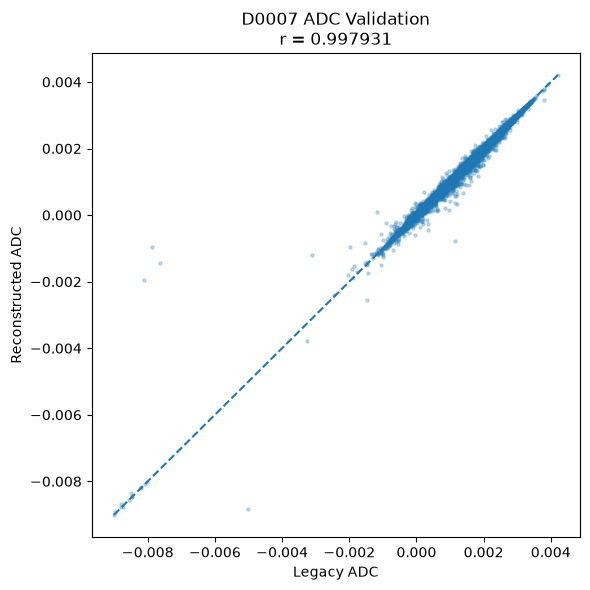

In [133]:
# ============================================================
# ADC VOXEL-WISE SCATTER PLOTS
# ============================================================

for subject in SUBJECTS:

    if subject not in ADC_COMPARISON:

        continue


    old_values = ADC_COMPARISON[
        subject
    ]["old_values"]

    new_values = ADC_COMPARISON[
        subject
    ]["new_values"]


    # Plot at most 100,000 voxels.
    max_points = 100000


    if len(old_values) > max_points:

        rng = np.random.default_rng(
            0
        )

        indices = rng.choice(
            len(old_values),
            size=max_points,
            replace=False,
        )

        x = old_values[
            indices
        ]

        y = new_values[
            indices
        ]

    else:

        x = old_values
        y = new_values


    correlation = np.corrcoef(
        old_values,
        new_values,
    )[0, 1]


    lower = min(
        float(x.min()),
        float(y.min()),
    )


    upper = max(
        float(x.max()),
        float(y.max()),
    )


    plt.figure(
        figsize=(6, 6)
    )

    plt.scatter(
        x,
        y,
        s=5,
        alpha=0.25,
    )

    plt.plot(
        [lower, upper],
        [lower, upper],
        linestyle="--",
    )

    plt.xlabel(
        "Legacy ADC"
    )

    plt.ylabel(
        "Reconstructed ADC"
    )

    plt.title(
        f"{subject} ADC Validation\n"
        f"r = {correlation:.6f}"
    )

    plt.tight_layout()

    plt.show()

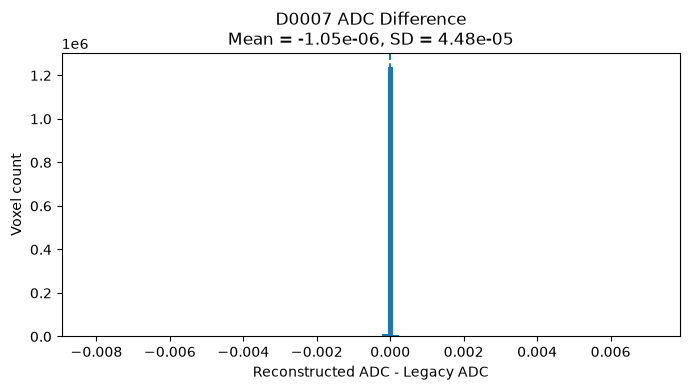

In [134]:
# ============================================================
# ADC DIFFERENCE DISTRIBUTION
# ============================================================

for subject in SUBJECTS:

    if subject not in ADC_COMPARISON:

        continue


    difference = ADC_COMPARISON[
        subject
    ]["difference"]


    mean_difference = np.mean(
        difference
    )

    sd_difference = np.std(
        difference
    )


    plt.figure(
        figsize=(7, 4)
    )

    plt.hist(
        difference,
        bins=100,
    )

    plt.axvline(
        0,
        linestyle="--",
    )

    plt.xlabel(
        "Reconstructed ADC - Legacy ADC"
    )

    plt.ylabel(
        "Voxel count"
    )

    plt.title(
        f"{subject} ADC Difference\n"
        f"Mean = {mean_difference:.2e}, "
        f"SD = {sd_difference:.2e}"
    )

    plt.tight_layout()

    plt.show()

### 2.3 Diffusion Metric Validation Summary

Diffusion metric validation was performed independently for D0007 and S00775.

For D0007, the reconstructed ADC image and the corresponding legacy pipeline output are available at compatible image geometry, allowing direct voxel-wise comparison using spatial correlation and absolute numerical error metrics.

For S00775, the reconstructed ADC image is available at the upsampled 0.5-mm resolution, whereas the available legacy ADC/MD image used for comparison is stored at the original lower-resolution grid. A directly corresponding legacy ADC image at the same reconstructed resolution is therefore not available for voxel-wise comparison.

No additional resampling is introduced solely for validation, because this would add interpolation-related differences that are not part of the reconstructed pipeline itself.

For S00775, reproducibility is therefore evaluated primarily through the downstream end-to-end analysis, including registration, transformed cortical trajectories, cortical region assignment, trajectory-level ADC profiles, and regional mean ADC depth profiles.

The absence of a directly corresponding intermediate legacy ADC image does not by itself indicate a pipeline failure. Final reproducibility is determined primarily by agreement in the downstream cortical-column outputs.

## 3. Registration Validation

The next stage evaluates the reconstructed DWI-to-T1 registration used to map cortical trajectories between anatomical and diffusion image spaces.

The registration stage is critical because cortical trajectories are initially defined from the FreeSurfer white and pial surfaces in T1 anatomical space, whereas ADC values are sampled from diffusion space.

For each subject, this section evaluates:

- availability of the reconstructed registration transform,
- geometry of the diffusion registration reference,
- geometry of the FreeSurfer anatomical reference,
- consistency of the registration inputs,
- availability of the corresponding legacy registration transform when present.

The registration transform itself is not interpreted only by numerical matrix similarity, because differences in software versions, registration initialization, or file conventions may produce numerically different transforms while preserving equivalent anatomical alignment.

Registration reproducibility is therefore assessed together with downstream transformed cortical trajectories and cortical profile agreement.

In [135]:
# ============================================================
# SECTION 3
# REGISTRATION CONFIGURATION
# ============================================================

REGISTRATION_PATHS = {

    "D0007": {

        "new_transform":
            SUBJECT_CONFIG["D0007"]
            ["new_transform"],

        "new_reference":
            NEW_ROOT
            / "D0007"
            / "preprocess"
            / "diffusion"
            / "D0007_dwi_masked.nii.gz",

        "freesurfer_orig":
            NEW_ROOT
            / "D0007"
            / "preprocess"
            / "freesurfer"
            / "D0007"
            / "mri"
            / "orig.mgz",
    },


    "S00775": {

        "new_transform":
            SUBJECT_CONFIG["S00775"]
            ["new_transform"],

        "new_reference":
            NEW_ROOT
            / "S00775"
            / "analysis"
            / "registration"
            / "S00775_dwi_sum_masked_upsampled.nii.gz",

        "freesurfer_orig":
            NEW_ROOT
            / "S00775"
            / "preprocess"
            / "freesurfer"
            / "S00775"
            / "mri"
            / "orig.mgz",
    },
}

In [136]:
# ============================================================
# REGISTRATION FILE AVAILABILITY
# ============================================================

registration_rows = []


for subject in SUBJECTS:

    paths = REGISTRATION_PATHS[
        subject
    ]

    transform = Path(
        paths["new_transform"]
    )

    reference = Path(
        paths["new_reference"]
    )

    fs_orig = Path(
        paths["freesurfer_orig"]
    )


    print()
    print("=" * 70)
    print(subject)
    print("=" * 70)

    print(
        "Transform:"
    )
    print(
        transform
    )
    print(
        "Exists:",
        transform.is_file(),
    )

    print()

    print(
        "DWI registration reference:"
    )
    print(
        reference
    )
    print(
        "Exists:",
        reference.is_file(),
    )

    print()

    print(
        "FreeSurfer orig.mgz:"
    )
    print(
        fs_orig
    )
    print(
        "Exists:",
        fs_orig.is_file(),
    )


    registration_rows.append({

        "Subject":
            subject,

        "Transform":
            transform.is_file(),

        "DWI reference":
            reference.is_file(),

        "FreeSurfer orig.mgz":
            fs_orig.is_file(),
    })


registration_availability_df = pd.DataFrame(
    registration_rows
)

display(
    registration_availability_df
)


D0007
Transform:
/mnt/newStor/paros/paros_WORK/xintong/test/new_pipeline/D0007/analysis/registration/D0007_DWI2T1_bet030.dat
Exists: True

DWI registration reference:
/mnt/newStor/paros/paros_WORK/xintong/test/new_pipeline/D0007/preprocess/diffusion/D0007_dwi_masked.nii.gz
Exists: True

FreeSurfer orig.mgz:
/mnt/newStor/paros/paros_WORK/xintong/test/new_pipeline/D0007/preprocess/freesurfer/D0007/mri/orig.mgz
Exists: True

S00775
Transform:
/mnt/newStor/paros/paros_WORK/xintong/test/new_pipeline/S00775/analysis/registration/S00775_DWI2T1.dat
Exists: True

DWI registration reference:
/mnt/newStor/paros/paros_WORK/xintong/test/new_pipeline/S00775/analysis/registration/S00775_dwi_sum_masked_upsampled.nii.gz
Exists: True

FreeSurfer orig.mgz:
/mnt/newStor/paros/paros_WORK/xintong/test/new_pipeline/S00775/preprocess/freesurfer/S00775/mri/orig.mgz
Exists: True


,Subject,Transform,DWI reference,FreeSurfer orig.mgz
0,D0007,True,True,True
1,S00775,True,True,True


In [137]:
# ============================================================
# REGISTRATION IMAGE GEOMETRY
# ============================================================

registration_geometry_rows = []


for subject in SUBJECTS:

    paths = REGISTRATION_PATHS[
        subject
    ]


    dwi_path = Path(
        paths["new_reference"]
    )

    t1_path = Path(
        paths["freesurfer_orig"]
    )


    if not dwi_path.is_file():

        raise FileNotFoundError(
            f"DWI registration reference not found:\n"
            f"{dwi_path}"
        )


    if not t1_path.is_file():

        raise FileNotFoundError(
            f"FreeSurfer orig.mgz not found:\n"
            f"{t1_path}"
        )


    dwi_img = nib.load(
        dwi_path
    )

    t1_img = nib.load(
        t1_path
    )


    dwi_shape = (
        dwi_img.shape
    )

    t1_shape = (
        t1_img.shape
    )


    dwi_spacing = tuple(
        float(v)
        for v in
        dwi_img.header.get_zooms()[:3]
    )

    t1_spacing = tuple(
        float(v)
        for v in
        t1_img.header.get_zooms()[:3]
    )


    print()
    print("=" * 70)
    print(subject)
    print("=" * 70)

    print(
        "DWI reference shape:",
        dwi_shape,
    )

    print(
        "DWI reference spacing:",
        dwi_spacing,
    )

    print()

    print(
        "T1 orig.mgz shape:",
        t1_shape,
    )

    print(
        "T1 orig.mgz spacing:",
        t1_spacing,
    )


    registration_geometry_rows.append({

        "Subject":
            subject,

        "DWI shape":
            str(
                dwi_shape
            ),

        "DWI spacing":
            str(
                tuple(
                    np.round(
                        dwi_spacing,
                        4,
                    )
                )
            ),

        "T1 shape":
            str(
                t1_shape
            ),

        "T1 spacing":
            str(
                tuple(
                    np.round(
                        t1_spacing,
                        4,
                    )
                )
            ),
    })


registration_geometry_df = pd.DataFrame(
    registration_geometry_rows
)

display(
    registration_geometry_df
)


D0007
DWI reference shape: (164, 328, 122)
DWI reference spacing: (1.0, 1.0, 1.0)

T1 orig.mgz shape: (np.int32(256), np.int32(256), np.int32(256))
T1 orig.mgz spacing: (1.0, 1.0, 1.0)

S00775
DWI reference shape: (512, 512, 272)
DWI reference spacing: (0.5, 0.5, 0.5)

T1 orig.mgz shape: (np.int32(256), np.int32(256), np.int32(256))
T1 orig.mgz spacing: (1.0, 1.0, 1.0)


,Subject,DWI shape,DWI spacing,T1 shape,T1 spacing
0,D0007,"(164, 328, 122)","(np.float64(1.0), np.float64(1.0), np.float64(...","(np.int32(256), np.int32(256), np.int32(256))","(np.float64(1.0), np.float64(1.0), np.float64(..."
1,S00775,"(512, 512, 272)","(np.float64(0.5), np.float64(0.5), np.float64(...","(np.int32(256), np.int32(256), np.int32(256))","(np.float64(1.0), np.float64(1.0), np.float64(..."


### 3.3 Registration Validation Summary

Both validation subjects are checked for the reconstructed DWI-to-T1 transform and the corresponding anatomical and diffusion registration references.

The registration inputs are allowed to differ in voxel dimensions and spatial resolution because they represent distinct T1 and diffusion image spaces.

The registration transform is considered an intermediate spatial mapping rather than a standalone scientific output. Its validity is therefore evaluated primarily through its downstream effect on cortical trajectory coordinates.

The next validation stage directly evaluates whether the reconstructed cortical trajectories are transformed consistently from T1 space into diffusion space.

## 4. Cortical Trajectory Validation

Cortical trajectories are generated between the FreeSurfer white and pial surfaces and sampled at 21 evenly spaced depth points.

The trajectories are first defined in anatomical T1 space and are then transformed into diffusion voxel space using the subject-specific DWI-to-T1 registration.

For each subject, this section validates:

- availability of white–pial pair files,
- availability of T1-space trajectories,
- availability of DWI-space trajectories,
- trajectory array dimensions,
- preservation of the expected 21 depth samples,
- numerical consistency between legacy and reconstructed trajectories when corresponding legacy files are available.

The primary goal is to verify that the reconstructed registration produces valid diffusion-space cortical trajectories before regional ADC sampling.

In [138]:
# ============================================================
# SECTION 4
# TRAJECTORY FILE DISCOVERY
# ============================================================

TRAJECTORY_FILES = {}


for subject in SUBJECTS:

    cfg = SUBJECT_CONFIG[subject]

    new_dir = Path(
        cfg["new_trajectories"]
    )

    old_root = Path(
        cfg["old_root"]
    )


    print()
    print("=" * 70)
    print(subject)
    print("=" * 70)


    # --------------------------------------------------------
    # Reconstructed files
    # --------------------------------------------------------

    new_pairs = sorted(
        new_dir.glob(
            f"{subject}_pair_*.mat"
        )
    )

    new_t1 = sorted(
        new_dir.glob(
            f"{subject}_trajectory_[lr]h.mat"
        )
    )

    new_dwi = sorted(
        new_dir.glob(
            f"{subject}_trajectory_[lr]h_dwi.mat"
        )
    )


    # --------------------------------------------------------
    # Search legacy outputs recursively
    # --------------------------------------------------------

    old_pairs = sorted(
        old_root.rglob(
            f"*{subject}*pair*.mat"
        )
    )

    old_t1 = sorted(
        p
        for p in old_root.rglob(
            f"*{subject}*trajectory*.mat"
        )
        if "dwi" not in p.name.lower()
    )

    old_dwi = sorted(
        old_root.rglob(
            f"*{subject}*trajectory*dwi*.mat"
        )
    )


    TRAJECTORY_FILES[
        subject
    ] = {

        "new_pairs":
            new_pairs,

        "new_t1":
            new_t1,

        "new_dwi":
            new_dwi,

        "old_pairs":
            old_pairs,

        "old_t1":
            old_t1,

        "old_dwi":
            old_dwi,
    }


    print()
    print("Reconstructed pair files:")
    for path in new_pairs:
        print(" ", path)

    print()
    print("Reconstructed T1 trajectories:")
    for path in new_t1:
        print(" ", path)

    print()
    print("Reconstructed DWI trajectories:")
    for path in new_dwi:
        print(" ", path)

    print()
    print("Legacy pair candidates:")
    for path in old_pairs:
        print(" ", path)

    print()
    print("Legacy T1 trajectory candidates:")
    for path in old_t1:
        print(" ", path)

    print()
    print("Legacy DWI trajectory candidates:")
    for path in old_dwi:
        print(" ", path)


D0007

Reconstructed pair files:
  /mnt/newStor/paros/paros_WORK/xintong/test/new_pipeline/D0007/analysis/trajectories/D0007_pair_lh.mat
  /mnt/newStor/paros/paros_WORK/xintong/test/new_pipeline/D0007/analysis/trajectories/D0007_pair_rh.mat

Reconstructed T1 trajectories:
  /mnt/newStor/paros/paros_WORK/xintong/test/new_pipeline/D0007/analysis/trajectories/D0007_trajectory_lh.mat
  /mnt/newStor/paros/paros_WORK/xintong/test/new_pipeline/D0007/analysis/trajectories/D0007_trajectory_rh.mat

Reconstructed DWI trajectories:
  /mnt/newStor/paros/paros_WORK/xintong/test/new_pipeline/D0007/analysis/trajectories/D0007_trajectory_lh_dwi.mat
  /mnt/newStor/paros/paros_WORK/xintong/test/new_pipeline/D0007/analysis/trajectories/D0007_trajectory_rh_dwi.mat

Legacy pair candidates:
  /mnt/newStor/paros/paros_WORK/xintong/test/existing_pipeline/output/D0007/columns/D0007_pair_lh.mat
  /mnt/newStor/paros/paros_WORK/xintong/test/existing_pipeline/output/D0007/columns/D0007_pair_rh.mat

Legacy T1 traje

### 4.1 Reconstructed Trajectory Structure

The reconstructed trajectory files are inspected before numerical comparison.

A valid cortical trajectory representation is expected to contain one trajectory per cortical surface vertex or white–pial pair, with 21 sampling locations spanning cortical depth.

The exact MAT-file variable names may differ between processing stages, so the file contents are inspected directly before extracting trajectory arrays.

In [139]:
# ============================================================
# INSPECT TRAJECTORY MAT FILE STRUCTURE
# ============================================================

from scipy.io import loadmat


def inspect_mat(path):

    mat = loadmat(
        path
    )

    variables = {}

    for key, value in mat.items():

        if key.startswith("__"):
            continue

        if isinstance(
            value,
            np.ndarray,
        ):

            variables[key] = {
                "shape": value.shape,
                "dtype": str(value.dtype),
            }

    return variables


for subject in SUBJECTS:

    print()
    print("=" * 70)
    print(subject)
    print("=" * 70)

    for category in [
        "new_pairs",
        "new_t1",
        "new_dwi",
    ]:

        print()
        print(category)
        print("-" * 70)

        for path in TRAJECTORY_FILES[
            subject
        ][category]:

            print()
            print(path.name)

            info = inspect_mat(
                path
            )

            for key, meta in info.items():

                print(
                    f"  {key:30s} "
                    f"{str(meta['shape']):20s} "
                    f"{meta['dtype']}"
                )


D0007

new_pairs
----------------------------------------------------------------------

D0007_pair_lh.mat
  lh_pair                        (120251, 6)          float64

D0007_pair_rh.mat
  rh_pair                        (119685, 6)          float64

new_t1
----------------------------------------------------------------------

D0007_trajectory_lh.mat
  lh_trajectory_points           (2525271, 3)         float64

D0007_trajectory_rh.mat
  rh_trajectory_points           (2513385, 3)         float64

new_dwi
----------------------------------------------------------------------

D0007_trajectory_lh_dwi.mat
  lh_trajectory_dwi              (4, 2525271)         float64

D0007_trajectory_rh_dwi.mat
  rh_trajectory_dwi              (4, 2513385)         float64

S00775

new_pairs
----------------------------------------------------------------------

S00775_pair_lh.mat
  lh_pair                        (125751, 6)          float64

S00775_pair_rh.mat
  rh_pair                        (128129, 

In [140]:
# ============================================================
# TRAJECTORY ARRAY EXTRACTION
# ============================================================

def extract_numeric_arrays(path):

    mat = loadmat(
        path
    )

    arrays = {}

    for key, value in mat.items():

        if key.startswith("__"):
            continue

        if not isinstance(
            value,
            np.ndarray,
        ):
            continue

        if not np.issubdtype(
            value.dtype,
            np.number,
        ):
            continue

        arrays[key] = np.asarray(
            value,
            dtype=float,
        )

    return arrays


def choose_trajectory_array(path):

    arrays = extract_numeric_arrays(
        path
    )

    candidates = []

    for key, arr in arrays.items():

        if arr.ndim < 2:
            continue

        score = 0

        name = key.lower()

        if "trajectory" in name:
            score += 10

        if "coord" in name:
            score += 5

        if 21 in arr.shape:
            score += 5

        if 3 in arr.shape:
            score += 3

        candidates.append(
            (
                score,
                key,
                arr,
            )
        )


    if not candidates:

        raise RuntimeError(
            f"No trajectory-like numeric array found in:\n{path}"
        )


    candidates.sort(
        key=lambda x: x[0],
        reverse=True,
    )


    score, key, arr = candidates[0]

    return key, arr


TRAJECTORY_ARRAYS = {}


for subject in SUBJECTS:

    TRAJECTORY_ARRAYS[
        subject
    ] = {}


    print()
    print("=" * 70)
    print(subject)
    print("=" * 70)


    for category in [
        "new_pairs",
        "new_t1",
        "new_dwi",
    ]:

        TRAJECTORY_ARRAYS[
            subject
        ][category] = []


        for path in TRAJECTORY_FILES[
            subject
        ][category]:

            key, arr = choose_trajectory_array(
                path
            )


            TRAJECTORY_ARRAYS[
                subject
            ][category].append(
                {
                    "path": path,
                    "key": key,
                    "array": arr,
                }
            )


            print(
                f"{category:12s}  "
                f"{path.name:45s}  "
                f"{key:25s}  "
                f"{arr.shape}"
            )


D0007
new_pairs     D0007_pair_lh.mat                              lh_pair                    (120251, 6)
new_pairs     D0007_pair_rh.mat                              rh_pair                    (119685, 6)
new_t1        D0007_trajectory_lh.mat                        lh_trajectory_points       (2525271, 3)
new_t1        D0007_trajectory_rh.mat                        rh_trajectory_points       (2513385, 3)
new_dwi       D0007_trajectory_lh_dwi.mat                    lh_trajectory_dwi          (4, 2525271)
new_dwi       D0007_trajectory_rh_dwi.mat                    rh_trajectory_dwi          (4, 2513385)

S00775
new_pairs     S00775_pair_lh.mat                             lh_pair                    (125751, 6)
new_pairs     S00775_pair_rh.mat                             rh_pair                    (128129, 6)
new_t1        S00775_trajectory_lh.mat                       lh_trajectory_points       (2640771, 3)
new_t1        S00775_trajectory_rh.mat                       rh_trajectory_point

### 4.2 Trajectory Dimensions and Depth Sampling

The reconstructed trajectory files store cortical depth samples in flattened form rather than as explicit `(N trajectories × 21 depths × 3 coordinates)` arrays.

For each hemisphere:

- the white–pial pair file contains one row per cortical trajectory,
- each trajectory contains 21 evenly spaced cortical depth samples,
- the T1-space trajectory file stores the resulting `N × 21` sample points as a flattened `(N × 21, 3)` array,
- the DWI-space trajectory file stores the same points as homogeneous coordinates with shape `(4, N × 21)`.

Therefore, preservation of the expected 21-point cortical depth sampling is evaluated by comparing the number of trajectory points with the number of white–pial pairs.

In [141]:
## ============================================================
# VALIDATE 21-POINT TRAJECTORY STRUCTURE
# ============================================================

trajectory_structure_rows = []


for subject in SUBJECTS:

    files = TRAJECTORY_FILES[subject]


    for hemi in ["lh", "rh"]:

        # ----------------------------------------------------
        # Find hemisphere-specific files
        # ----------------------------------------------------

        pair_path = next(
            p for p in files["new_pairs"]
            if f"_pair_{hemi}.mat" in p.name
        )

        t1_path = next(
            p for p in files["new_t1"]
            if f"_trajectory_{hemi}.mat" in p.name
        )

        dwi_path = next(
            p for p in files["new_dwi"]
            if f"_trajectory_{hemi}_dwi.mat" in p.name
        )


        # ----------------------------------------------------
        # Load arrays
        # ----------------------------------------------------

        pair_key, pair_array = choose_trajectory_array(
            pair_path
        )

        t1_key, t1_array = choose_trajectory_array(
            t1_path
        )

        dwi_key, dwi_array = choose_trajectory_array(
            dwi_path
        )


        # ----------------------------------------------------
        # Expected number of points
        # ----------------------------------------------------

        n_trajectories = pair_array.shape[0]

        expected_points = (
            n_trajectories * 21
        )

        actual_t1_points = (
            t1_array.shape[0]
        )

        actual_dwi_points = (
            dwi_array.shape[1]
        )


        t1_valid = (
            actual_t1_points
            == expected_points
        )

        dwi_valid = (
            actual_dwi_points
            == expected_points
        )


        trajectory_structure_rows.append({

            "Subject":
                subject,

            "Hemisphere":
                hemi.upper(),

            "Trajectories":
                n_trajectories,

            "Expected points (N×21)":
                expected_points,

            "T1 points":
                actual_t1_points,

            "DWI points":
                actual_dwi_points,

            "T1 = 21 depths":
                t1_valid,

            "DWI = 21 depths":
                dwi_valid,
        })


trajectory_structure_df = pd.DataFrame(
    trajectory_structure_rows
)

display(
    trajectory_structure_df
)

,Subject,Hemisphere,Trajectories,Expected points (N×21),T1 points,DWI points,T1 = 21 depths,DWI = 21 depths
0,D0007,LH,120251,2525271,2525271,2525271,True,True
1,D0007,RH,119685,2513385,2513385,2513385,True,True
2,S00775,LH,125751,2640771,2640771,2640771,True,True
3,S00775,RH,128129,2690709,2690709,2690709,True,True


### 4.3 Legacy vs. Reconstructed White–Pial Pair Structure

Where corresponding legacy pair files are available, the reconstructed white–pial cortical surface pairs are compared at the structural level.

Each pair contains the white-surface and pial-surface endpoints used to define one cortical trajectory.

The comparison focuses on:

- pair-file availability,
- array structure,
- number of white–pial pairs per hemisphere,
- consistency of the pair representation used to generate cortical trajectories.

Because the preserved legacy and reconstructed pair files contain different numbers of trajectories, direct row-wise numerical comparison is not performed.

This difference is documented at the raw pair stage, while the effect of trajectory filtering and bad-column removal is evaluated later using the cleaned regional and ADC profile outputs.

In [142]:
# ============================================================
# PAIR ARRAY LOADER
# ============================================================

def load_pair_array(path):

    mat = loadmat(path)

    candidates = []

    for key, value in mat.items():

        if key.startswith("__"):
            continue

        if not isinstance(value, np.ndarray):
            continue

        if not np.issubdtype(value.dtype, np.number):
            continue

        arr = np.asarray(
            value,
            dtype=float,
        )

        if arr.ndim != 2:
            continue

        # Standard format: (N, 6)
        if arr.shape[1] == 6:
            candidates.append(
                (
                    key,
                    arr,
                )
            )

        # Possible transposed legacy format: (6, N)
        elif arr.shape[0] == 6:
            candidates.append(
                (
                    key,
                    arr.T,
                )
            )


    if not candidates:

        raise RuntimeError(
            f"No pair array with 6 coordinates found in:\n{path}"
        )


    # Prefer variable names containing "pair"
    candidates.sort(
        key=lambda x:
            "pair" not in x[0].lower()
    )


    key, array = candidates[0]

    return key, array

In [143]:
# ============================================================
# 4.3 WHITE–PIAL PAIR COUNT COMPARISON
# ============================================================

pair_count_rows = []


for subject in SUBJECTS:

    files = TRAJECTORY_FILES[subject]

    for hemi in ["lh", "rh"]:

        new_candidates = [
            p for p in files["new_pairs"]
            if f"_pair_{hemi}.mat" in p.name
        ]

        old_candidates = [
            p for p in files["old_pairs"]
            if f"_pair_{hemi}.mat" in p.name
        ]


        if not new_candidates:

            raise FileNotFoundError(
                f"Reconstructed pair file missing: "
                f"{subject} {hemi}"
            )


        _, new_pair = load_pair_array(
            new_candidates[0]
        )

        new_count = new_pair.shape[0]


        if old_candidates:

            _, old_pair = load_pair_array(
                old_candidates[0]
            )

            old_count = old_pair.shape[0]

            difference = (
                new_count
                - old_count
            )

            percent_difference = (
                difference
                / old_count
                * 100
            )

            status = (
                "Same count"
                if difference == 0
                else "Different count"
            )

        else:

            old_count = np.nan
            difference = np.nan
            percent_difference = np.nan
            status = "Legacy unavailable"


        pair_count_rows.append({

            "Subject":
                subject,

            "Hemisphere":
                hemi.upper(),

            "Legacy pairs":
                old_count,

            "Reconstructed pairs":
                new_count,

            "Difference":
                difference,

            "Difference (%)":
                percent_difference,

            "Status":
                status,
        })


pair_count_df = pd.DataFrame(
    pair_count_rows
)

display(
    pair_count_df
)

,Subject,Hemisphere,Legacy pairs,Reconstructed pairs,Difference,Difference (%),Status
0,D0007,LH,118922,120251,1329,1.117539,Different count
1,D0007,RH,118767,119685,918,0.772942,Different count
2,S00775,LH,121365,125751,4386,3.613892,Different count
3,S00775,RH,123599,128129,4530,3.665078,Different count


## 5. Cortical Region Assignment Validation

After transformation into diffusion space, cortical trajectories are assigned to the 68 Desikan–Killiany cortical regions using FreeSurfer anatomical labels.

This section evaluates the reconstructed regional outputs after bad-column cleaning.

The validation includes:

- completeness of the 68 cortical regions,
- availability of regional MAT and CSV files,
- number of retained trajectories per region,
- total number of retained trajectories after cleaning,
- comparison of reconstructed and legacy regional trajectory counts when corresponding legacy outputs are available.

Because invalid trajectories are removed before regional profile aggregation, the regional outputs represent the effective cortical columns used in the final ADC analysis.

In [144]:
# ============================================================
# SECTION 5
# REGION FILE COMPLETENESS
# ============================================================

REGION_FILES = {}

region_completeness_rows = []


for subject in SUBJECTS:

    new_region_dir = Path(
        SUBJECT_CONFIG[
            subject
        ]["new_regions"]
    )


    new_mat = sorted(
        new_region_dir.glob(
            "*.mat"
        )
    )

    new_csv = sorted(
        new_region_dir.glob(
            "*.csv"
        )
    )


    REGION_FILES[
        subject
    ] = {
        "new_mat": new_mat,
        "new_csv": new_csv,
    }


    region_completeness_rows.append({

        "Subject":
            subject,

        "MAT files":
            len(new_mat),

        "CSV files":
            len(new_csv),

        "Expected regions":
            68,

        "MAT complete":
            len(new_mat) == 68,

        "CSV complete":
            len(new_csv) == 68,
    })


region_completeness_df = pd.DataFrame(
    region_completeness_rows
)

display(
    region_completeness_df
)

,Subject,MAT files,CSV files,Expected regions,MAT complete,CSV complete
0,D0007,68,68,68,True,True
1,S00775,68,68,68,True,True


### 5.1 Retained Trajectories After Cleaning

The number of trajectories retained in each cortical region is calculated from the cleaned regional CSV outputs.

The regional trajectory count may differ from the original white–pial pair count because trajectories containing invalid ADC samples are removed during bad-column cleaning.

The total number of retained trajectories therefore reflects the actual cortical columns used for regional ADC profile aggregation.

In [145]:
# ============================================================
# CLEANED TRAJECTORY COUNTS PER REGION
# ============================================================

region_count_rows = []


for subject in SUBJECTS:

    region_dir = Path(
        SUBJECT_CONFIG[
            subject
        ]["new_regions"]
    )

    csv_files = sorted(
        region_dir.glob("*.csv")
    )


    for path in csv_files:

        data = pd.read_csv(
            path,
            header=None,
        ).to_numpy()


        # ----------------------------------------------------
        # Regional DWI coordinates are expected as:
        #
        #   4 × (N trajectories × 21 depth points)
        #
        # Some files may be transposed, so normalize first.
        # ----------------------------------------------------

        if data.shape[0] == 4:

            n_points = data.shape[1]

        elif data.shape[1] == 4:

            n_points = data.shape[0]

        else:

            raise ValueError(
                f"Unexpected regional coordinate shape "
                f"for {path.name}: {data.shape}"
            )


        if n_points % 21 != 0:

            raise ValueError(
                f"Number of depth points is not divisible "
                f"by 21 for {path.name}: {n_points}"
            )


        n_trajectories = (
            n_points // 21
        )


        region_count_rows.append({

            "Subject":
                subject,

            "Region file":
                path.name,

            "Coordinate shape":
                str(data.shape),

            "Depth points":
                n_points,

            "Retained trajectories":
                n_trajectories,
        })


region_counts_df = pd.DataFrame(
    region_count_rows
)

display(
    region_counts_df
)

,Subject,Region file,Coordinate shape,Depth points,Retained trajectories
0,D0007,lh_bankssts.csv,"(4, 25221)",25221,1201
1,D0007,lh_caudalanteriorcingulate.csv,"(4, 17220)",17220,820
2,D0007,lh_caudalmiddlefrontal.csv,"(4, 65835)",65835,3135
3,D0007,lh_cuneus.csv,"(4, 48132)",48132,2292
4,D0007,lh_entorhinal.csv,"(4, 13944)",13944,664
...,...,...,...,...,...
131,S00775,rh_superiorparietal.csv,"(4, 152733)",152733,7273
132,S00775,rh_superiortemporal.csv,"(4, 121338)",121338,5778
133,S00775,rh_supramarginal.csv,"(4, 116025)",116025,5525
134,S00775,rh_temporalpole.csv,"(4, 10941)",10941,521


In [146]:
# ============================================================
# CLEANED REGIONAL TRAJECTORY SUMMARY
# ============================================================

region_count_summary = (

    region_counts_df

    .groupby(
        "Subject"
    )["Retained trajectories"]

    .agg(
        [
            "count",
            "min",
            "median",
            "mean",
            "max",
            "sum",
        ]
    )

    .reset_index()
)

display(
    region_count_summary
)

,Subject,count,min,median,mean,max,sum
0,D0007,68,322,2889.5,3276.926471,9163,222831
1,S00775,68,358,2810.5,3478.117647,9523,236512


### 5.2 Bad-Column Cleaning Summary

Trajectories containing invalid ADC samples are removed before regional profile aggregation.

A trajectory is treated as invalid if any of its sampled ADC values contains zero, NaN, or infinite values.

The cleaning record is inspected to quantify how many trajectories were removed from each reconstructed subject before final regional profile calculation.

In [147]:
# ============================================================
# BAD-COLUMN CLEANING SUMMARY
# ============================================================

import json


cleaning_rows = []


for subject in SUBJECTS:

    profile_dir = Path(
        SUBJECT_CONFIG[
            subject
        ]["new_profiles"]
    )


    json_path = (
        profile_dir
        / "bad_trajectories.json"
    )


    if not json_path.is_file():

        cleaning_rows.append({

            "Subject":
                subject,

            "Cleaning record":
                False,

            "Recorded bad trajectories":
                np.nan,
        })

        continue


    with open(
        json_path,
        "r",
    ) as f:

        bad_data = json.load(
            f
        )


    # --------------------------------------------------------
    # Count all stored bad indices recursively
    # --------------------------------------------------------

    def recursive_count(obj):

        if isinstance(
            obj,
            list,
        ):
            return len(obj)

        if isinstance(
            obj,
            dict,
        ):
            return sum(
                recursive_count(v)
                for v in obj.values()
            )

        return 0


    n_bad = recursive_count(
        bad_data
    )


    cleaning_rows.append({

        "Subject":
            subject,

        "Cleaning record":
            True,

        "Recorded bad trajectories":
            n_bad,
    })


cleaning_summary_df = pd.DataFrame(
    cleaning_rows
)

display(
    cleaning_summary_df
)

,Subject,Cleaning record,Recorded bad trajectories
0,D0007,True,838
1,S00775,True,245


## 5.3 Compare raw pair count vs cleaned regional count

In [148]:
# ============================================================
# RAW PAIRS VS CLEANED REGIONAL TRAJECTORIES
# ============================================================

flow_rows = []


for subject in SUBJECTS:

    # --------------------------------------------------------
    # Raw pair counts
    # --------------------------------------------------------

    raw_pairs = (
        pair_count_df[
            pair_count_df[
                "Subject"
            ] == subject
        ][
            "Reconstructed pairs"
        ]
        .sum()
    )


    # --------------------------------------------------------
    # Final cleaned region count
    # --------------------------------------------------------

    cleaned_count = (
        region_counts_df[
            region_counts_df[
                "Subject"
            ] == subject
        ][
            "Retained trajectories"
        ]
        .sum()
    )


    removed = (
        raw_pairs
        - cleaned_count
    )


    removal_fraction = (
        removed
        / raw_pairs
    )


    flow_rows.append({

        "Subject":
            subject,

        "Raw white–pial pairs":
            int(raw_pairs),

        "Cleaned regional trajectories":
            int(cleaned_count),

        "Removed before final analysis":
            int(removed),

        "Removed fraction":
            removal_fraction,
    })


trajectory_flow_df = pd.DataFrame(
    flow_rows
)

display(
    trajectory_flow_df
)

,Subject,Raw white–pial pairs,Cleaned regional trajectories,Removed before final analysis,Removed fraction
0,D0007,239936,222831,17105,0.07129
1,S00775,253880,236512,17368,0.06841


## 6. Trajectory-Level ADC Profile Validation

After cortical trajectories are assigned to anatomical regions and invalid trajectories are removed, ADC values are sampled along each cortical trajectory.

Each retained trajectory is expected to contain 21 ADC samples spanning cortical depth from the white-matter surface toward the pial surface.

This section evaluates:

- availability of trajectory-level ADC profile files,
- completeness of the 68 cortical regions,
- preservation of 21 depth samples per trajectory,
- number of retained trajectories within each region,
- compatibility between legacy and reconstructed trajectory-level profile outputs.

Direct trajectory-by-trajectory numerical comparison is performed only when the corresponding legacy and reconstructed regional profile files contain compatible trajectory sets.

In [149]:
# ============================================================
# SECTION 6
# RECONSTRUCTED TRAJECTORY-LEVEL ADC PROFILE STRUCTURE
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd


def load_trajectory_profile(path):

    path = Path(path)

    data = pd.read_csv(
        path,
        header=None,
    ).to_numpy(
        dtype=float
    )

    if data.ndim != 2:

        raise ValueError(
            f"Expected 2-D profile array: "
            f"{path.name} -> {data.shape}"
        )

    # Standard: N trajectories × 21 depths
    if data.shape[1] == 21:

        profile = data

    # Transposed: 21 depths × N trajectories
    elif data.shape[0] == 21:

        profile = data.T

    else:

        raise ValueError(
            f"No 21-depth dimension found: "
            f"{path.name} -> {data.shape}"
        )

    return profile


# ============================================================
# DISCOVER RECONSTRUCTED PROFILE FILES
# ============================================================

PROFILE_FILES = {}

new_profile_structure_rows = []


for subject in SUBJECTS:

    new_profile_dir = Path(
        SUBJECT_CONFIG[
            subject
        ]["new_profiles"]
    )

    new_profiles = sorted(
        new_profile_dir.glob(
            "*_adc.csv"
        )
    )

    PROFILE_FILES[
        subject
    ] = {
        "new": new_profiles
    }


    print()
    print("=" * 70)
    print(subject)
    print("=" * 70)
    print(
        "ADC profile files:",
        len(new_profiles)
    )


    for path in new_profiles:

        try:

            profile = load_trajectory_profile(
                path
            )

            new_profile_structure_rows.append({

                "Subject":
                    subject,

                "File":
                    path.name,

                "Trajectories":
                    profile.shape[0],

                "Depth samples":
                    profile.shape[1],

                "Finite":
                    bool(
                        np.isfinite(
                            profile
                        ).all()
                    ),

                "Contains zero":
                    bool(
                        np.any(
                            profile == 0
                        )
                    ),
            })


        except Exception as error:

            new_profile_structure_rows.append({

                "Subject":
                    subject,

                "File":
                    path.name,

                "Trajectories":
                    np.nan,

                "Depth samples":
                    np.nan,

                "Finite":
                    False,

                "Contains zero":
                    np.nan,

                "Error":
                    str(error),
            })


# ============================================================
# FULL PROFILE STRUCTURE TABLE
# ============================================================

new_profile_structure_df = pd.DataFrame(
    new_profile_structure_rows
)

display(
    new_profile_structure_df
)


# ============================================================
# PROFILE SUMMARY
# ============================================================

new_profile_summary_df = (

    new_profile_structure_df

    .groupby(
        "Subject"
    )

    .agg(

        Profile_files=(
            "File",
            "count",
        ),

        Min_trajectories=(
            "Trajectories",
            "min",
        ),

        Median_trajectories=(
            "Trajectories",
            "median",
        ),

        Mean_trajectories=(
            "Trajectories",
            "mean",
        ),

        Max_trajectories=(
            "Trajectories",
            "max",
        ),

        Total_trajectories=(
            "Trajectories",
            "sum",
        ),

        All_21_depths=(
            "Depth samples",
            lambda x: bool(
                (x == 21).all()
            ),
        ),

        All_finite=(
            "Finite",
            "all",
        ),

        Any_zero=(
            "Contains zero",
            "any",
        ),
    )

    .reset_index()
)

display(
    new_profile_summary_df
)


D0007
ADC profile files: 68

S00775
ADC profile files: 68


,Subject,File,Trajectories,Depth samples,Finite,Contains zero
0,D0007,D0007_lh_bankssts_adc.csv,1201,21,True,False
1,D0007,D0007_lh_caudalanteriorcingulate_adc.csv,820,21,True,False
2,D0007,D0007_lh_caudalmiddlefrontal_adc.csv,3135,21,True,False
3,D0007,D0007_lh_cuneus_adc.csv,2292,21,True,False
4,D0007,D0007_lh_entorhinal_adc.csv,664,21,True,False
...,...,...,...,...,...,...
131,S00775,S00775_rh_superiorparietal_adc.csv,7273,21,True,False
132,S00775,S00775_rh_superiortemporal_adc.csv,5778,21,True,False
133,S00775,S00775_rh_supramarginal_adc.csv,5525,21,True,False
134,S00775,S00775_rh_temporalpole_adc.csv,521,21,True,False


,Subject,Profile_files,Min_trajectories,Median_trajectories,Mean_trajectories,Max_trajectories,Total_trajectories,All_21_depths,All_finite,Any_zero
0,D0007,68,322,2889.5,3276.926471,9163,222831,True,True,False
1,S00775,68,358,2810.5,3478.117647,9523,236512,True,True,False


### 6.2 Legacy vs. Reconstructed Trajectory-Level ADC Profiles

The reconstructed trajectory-level ADC profiles are compared with the corresponding legacy pipeline outputs where compatible regional files are available.

Each profile contains ADC values sampled at 21 cortical depth locations for every retained trajectory within a cortical region.

The comparison evaluates:

- availability of corresponding legacy and reconstructed regional profile files,
- number of trajectories per region,
- preservation of the 21-depth structure,
- trajectory-level numerical agreement when the retained trajectory sets are directly compatible.

If the legacy and reconstructed files contain different numbers of retained trajectories, direct row-wise comparison is not performed. These regions are carried forward to the regional mean profile comparison, which provides the primary end-to-end validation.

In [150]:
# ============================================================
# 6.2 MATCH LEGACY AND RECONSTRUCTED TRAJECTORY-LEVEL PROFILES
# ============================================================

import re


def normalize_profile_name(name):

    name = name.lower()

    # Remove extension
    name = re.sub(
        r"\.csv$",
        "",
        name,
    )

    # Remove metric suffix
    name = re.sub(
        r"_(adc|md)$",
        "",
        name,
    )

    # Legacy trajectory-level profile marker
    name = re.sub(
        r"_cols$",
        "",
        name,
    )

    # Remove subject prefix
    name = re.sub(
        r"^(d0007|s00775)_",
        "",
        name,
    )

    return name


PROFILE_MATCHES = {}


for subject in SUBJECTS:

    new_files = PROFILE_FILES[
        subject
    ]["new"]


    # --------------------------------------------------------
    # Keep only actual legacy regional trajectory profiles
    # --------------------------------------------------------

    old_files = [

        p for p in LEGACY_PROFILE_FILES[
            subject
        ]

        if (
            "_cols_adc.csv"
            in p.name.lower()

            and "summary"
            not in p.name.lower()

            and "qa"
            not in p.name.lower()
        )
    ]


    new_map = {

        normalize_profile_name(
            p.name
        ):
            p

        for p in new_files
    }


    old_map = {

        normalize_profile_name(
            p.name
        ):
            p

        for p in old_files
    }


    common_keys = sorted(
        set(new_map.keys())
        &
        set(old_map.keys())
    )


    PROFILE_MATCHES[
        subject
    ] = [

        (
            key,
            old_map[key],
            new_map[key],
        )

        for key in common_keys
    ]


    print()
    print("=" * 70)
    print(subject)
    print("=" * 70)

    print(
        "New regional profiles:",
        len(new_files),
    )

    print(
        "Legacy regional profiles:",
        len(old_files),
    )

    print(
        "Matched profiles:",
        len(common_keys),
    )


    # --------------------------------------------------------
    # Report unmatched files
    # --------------------------------------------------------

    unmatched_new = sorted(
        set(new_map)
        -
        set(old_map)
    )

    unmatched_old = sorted(
        set(old_map)
        -
        set(new_map)
    )


    if unmatched_new:

        print()
        print("Unmatched NEW:")
        for key in unmatched_new:
            print(" ", key)


    if unmatched_old:

        print()
        print("Unmatched LEGACY:")
        for key in unmatched_old:
            print(" ", key)


D0007
New regional profiles: 68
Legacy regional profiles: 68
Matched profiles: 68

S00775
New regional profiles: 68
Legacy regional profiles: 68
Matched profiles: 68


In [151]:
# ============================================================
# TRAJECTORY-LEVEL PROFILE COMPARISON
# ============================================================

trajectory_profile_comparison_rows = []


for subject in SUBJECTS:

    for (
        region,
        old_path,
        new_path,
    ) in PROFILE_MATCHES[
        subject
    ]:

        old_profile = load_trajectory_profile(
            old_path
        )

        new_profile = load_trajectory_profile(
            new_path
        )


        same_shape = (
            old_profile.shape
            == new_profile.shape
        )


        if not same_shape:

            trajectory_profile_comparison_rows.append({

                "Subject":
                    subject,

                "Region":
                    region,

                "Legacy trajectories":
                    old_profile.shape[0],

                "Reconstructed trajectories":
                    new_profile.shape[0],

                "Depth samples":
                    new_profile.shape[1],

                "Status":
                    "Different trajectory count",

                "Correlation":
                    np.nan,

                "MAE":
                    np.nan,

                "RMSE":
                    np.nan,
            })

            continue


        old_values = (
            old_profile.ravel()
        )

        new_values = (
            new_profile.ravel()
        )


        valid = (
            np.isfinite(old_values)
            &
            np.isfinite(new_values)
        )


        old_values = (
            old_values[valid]
        )

        new_values = (
            new_values[valid]
        )


        difference = (
            new_values
            -
            old_values
        )


        correlation = np.corrcoef(
            old_values,
            new_values,
        )[0, 1]


        mae = np.mean(
            np.abs(
                difference
            )
        )


        rmse = np.sqrt(
            np.mean(
                difference ** 2
            )
        )


        trajectory_profile_comparison_rows.append({

            "Subject":
                subject,

            "Region":
                region,

            "Legacy trajectories":
                old_profile.shape[0],

            "Reconstructed trajectories":
                new_profile.shape[0],

            "Depth samples":
                new_profile.shape[1],

            "Status":
                "Compared",

            "Correlation":
                correlation,

            "MAE":
                mae,

            "RMSE":
                rmse,
        })


trajectory_profile_comparison_df = pd.DataFrame(
    trajectory_profile_comparison_rows
)

display(
    trajectory_profile_comparison_df
)

,Subject,Region,Legacy trajectories,Reconstructed trajectories,Depth samples,Status,Correlation,MAE,RMSE
0,D0007,lh_bankssts,1201,1201,21,Compared,0.55067,0.000172,0.000269
1,D0007,lh_caudalanteriorcingulate,800,820,21,Different trajectory count,NaN,NaN,NaN
2,D0007,lh_caudalmiddlefrontal,3180,3135,21,Different trajectory count,NaN,NaN,NaN
3,D0007,lh_cuneus,2378,2292,21,Different trajectory count,NaN,NaN,NaN
4,D0007,lh_entorhinal,569,664,21,Different trajectory count,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...
131,S00775,rh_superiorparietal,7025,7273,21,Different trajectory count,NaN,NaN,NaN
132,S00775,rh_superiortemporal,5736,5778,21,Different trajectory count,NaN,NaN,NaN
133,S00775,rh_supramarginal,5386,5525,21,Different trajectory count,NaN,NaN,NaN
134,S00775,rh_temporalpole,526,521,21,Different trajectory count,NaN,NaN,NaN


### 6.3 Trajectory-Level Profile Validation Summary

Trajectory-level ADC profiles were successfully generated for all 68 cortical regions with 21 depth samples per trajectory.

The number of retained trajectories differs between the legacy and reconstructed pipelines in many regions. Therefore, direct row-wise numerical comparison is not considered a reliable measure of reproducibility, because individual trajectories cannot be assumed to have identical identities or ordering across the two outputs.

Even when two regional files contain the same number of trajectories, equal row counts alone do not establish one-to-one trajectory correspondence.

Trajectory-level validation is therefore used primarily to confirm profile structure, depth sampling, and valid ADC coverage. Quantitative end-to-end reproducibility is evaluated at the regional mean profile level, where each cortical region is represented by a common 21-point ADC depth profile.

## 7. Regional Mean ADC Profile Validation

The final cortical-column output is represented as a mean ADC profile for each of the 68 Desikan–Killiany cortical regions.

Each regional profile contains 21 values describing the average ADC signal across cortical depth.

Unlike trajectory-level comparison, regional mean profiles do not require one-to-one correspondence between individual cortical trajectories. This makes them the primary output for evaluating end-to-end reproducibility between the legacy and reconstructed pipelines.

This section evaluates:

- completeness of the 68 regional mean profiles,
- preservation of the 21-depth representation,
- region-wise correlation,
- mean absolute error (MAE),
- root mean squared error (RMSE),
- mean numerical difference,
- agreement across the complete 68 × 21 cortical-depth representation.

In [152]:
# ============================================================
# SECTION 7
# REGIONAL MEAN ADC PROFILE DISCOVERY
# ============================================================

REGIONAL_MEAN_FILES = {}


for subject in SUBJECTS:

    new_dir = Path(
        SUBJECT_CONFIG[
            subject
        ]["new_regional_profiles"]
    )

    old_dir = Path(
        SUBJECT_CONFIG[
            subject
        ]["old_regional_profiles"]
    )


    new_files = sorted(
        new_dir.glob(
            "*_adc_mean.csv"
        )
    )

    old_files = sorted(
        old_dir.glob(
            "*.csv"
        )
    )


    REGIONAL_MEAN_FILES[
        subject
    ] = {
        "old": old_files,
        "new": new_files,
    }


    print()
    print("=" * 70)
    print(subject)
    print("=" * 70)

    print(
        "Legacy regional means:",
        len(old_files),
    )

    print(
        "Reconstructed regional means:",
        len(new_files),
    )

    print()
    print("Legacy examples:")

    for p in old_files[:5]:
        print(" ", p.name)

    print()
    print("Reconstructed examples:")

    for p in new_files[:5]:
        print(" ", p.name)


D0007
Legacy regional means: 68
Reconstructed regional means: 68

Legacy examples:
  D0007_lh_bankssts_cols_adc_mean.csv
  D0007_lh_caudalanteriorcingulate_cols_adc_mean.csv
  D0007_lh_caudalmiddlefrontal_cols_adc_mean.csv
  D0007_lh_cuneus_cols_adc_mean.csv
  D0007_lh_entorhinal_cols_adc_mean.csv

Reconstructed examples:
  D0007_lh_bankssts_adc_mean.csv
  D0007_lh_caudalanteriorcingulate_adc_mean.csv
  D0007_lh_caudalmiddlefrontal_adc_mean.csv
  D0007_lh_cuneus_adc_mean.csv
  D0007_lh_entorhinal_adc_mean.csv

S00775
Legacy regional means: 68
Reconstructed regional means: 68

Legacy examples:
  S00775_lh_bankssts_cols_adc_mean.csv
  S00775_lh_caudalanteriorcingulate_cols_adc_mean.csv
  S00775_lh_caudalmiddlefrontal_cols_adc_mean.csv
  S00775_lh_cuneus_cols_adc_mean.csv
  S00775_lh_entorhinal_cols_adc_mean.csv

Reconstructed examples:
  S00775_lh_bankssts_adc_mean.csv
  S00775_lh_caudalanteriorcingulate_adc_mean.csv
  S00775_lh_caudalmiddlefrontal_adc_mean.csv
  S00775_lh_cuneus_adc_me

### 7.1 Regional Mean Profile Matching

Legacy and reconstructed regional mean files are matched by hemisphere and cortical region name.

Differences in filename conventions are normalized before matching so that each anatomical region is compared with its corresponding output from the other pipeline.

A complete match is expected to contain 68 cortical regions per subject.

In [153]:
# ============================================================
# NORMALIZE REGIONAL MEAN PROFILE NAMES
# ============================================================

def normalize_regional_mean_name(name):

    name = name.lower()

    # Remove extension
    name = re.sub(
        r"\.csv$",
        "",
        name,
    )

    # Remove subject prefix
    name = re.sub(
        r"^(d0007|s00775)_",
        "",
        name,
    )

    # Remove metric / aggregation suffixes
    name = re.sub(
        r"_(adc|md)_mean$",
        "",
        name,
    )

    name = re.sub(
        r"_mean_(adc|md)$",
        "",
        name,
    )

    name = re.sub(
        r"_(adc|md)$",
        "",
        name,
    )

    name = re.sub(
        r"_cols_region_mean$",
        "",
        name,
    )

    name = re.sub(
        r"_cols_mean$",
        "",
        name,
    )

    name = re.sub(
        r"_mean$",
        "",
        name,
    )

    # Legacy regional mean files may retain "_cols"
    name = re.sub(
        r"_cols$",
        "",
        name,
    )

    return name
REGIONAL_MEAN_MATCHES = {}


for subject in SUBJECTS:

    old_files = REGIONAL_MEAN_FILES[
        subject
    ]["old"]

    new_files = REGIONAL_MEAN_FILES[
        subject
    ]["new"]


    old_map = {
        normalize_regional_mean_name(
            p.name
        ): p
        for p in old_files
    }

    new_map = {
        normalize_regional_mean_name(
            p.name
        ): p
        for p in new_files
    }


    common_regions = sorted(
        set(old_map)
        &
        set(new_map)
    )


    REGIONAL_MEAN_MATCHES[
        subject
    ] = [
        (
            region,
            old_map[region],
            new_map[region],
        )
        for region in common_regions
    ]


    print()
    print("=" * 70)
    print(subject)
    print("=" * 70)

    print(
        "Legacy files:",
        len(old_files),
    )

    print(
        "Reconstructed files:",
        len(new_files),
    )

    print(
        "Matched regions:",
        len(common_regions),
    )


    unmatched_old = sorted(
        set(old_map)
        -
        set(new_map)
    )

    unmatched_new = sorted(
        set(new_map)
        -
        set(old_map)
    )


    if unmatched_old:

        print()
        print("Unmatched legacy:")

        for region in unmatched_old:
            print(" ", region)


    if unmatched_new:

        print()
        print("Unmatched reconstructed:")

        for region in unmatched_new:
            print(" ", region)


D0007
Legacy files: 68
Reconstructed files: 68
Matched regions: 68

S00775
Legacy files: 68
Reconstructed files: 68
Matched regions: 68


In [154]:
# ============================================================
# LOCATE S00775 REGIONAL MEAN FILES
# ============================================================

s00775_analysis = Path(
    SUBJECT_CONFIG["S00775"]["analysis_root"]
)

print("Analysis root:")
print(s00775_analysis)

print()
print("All CSV files containing mean:")
print("=" * 70)

mean_candidates = sorted(
    p
    for p in s00775_analysis.rglob("*.csv")
    if "mean" in p.name.lower()
)

for p in mean_candidates:
    print(p)

print()
print("Total:", len(mean_candidates))
print("Configured new_regional_profiles:")
print(
    SUBJECT_CONFIG[
        "S00775"
    ]["new_regional_profiles"]
)

print()

configured_dir = Path(
    SUBJECT_CONFIG[
        "S00775"
    ]["new_regional_profiles"]
)

print(
    "Directory exists:",
    configured_dir.is_dir()
)

print()

if configured_dir.is_dir():

    print("CSV files directly inside:")

    for p in sorted(
        configured_dir.glob("*.csv")
    ):
        print(p.name)

Analysis root:
/mnt/newStor/paros/paros_WORK/xintong/test/new_pipeline/S00775/analysis

All CSV files containing mean:
/mnt/newStor/paros/paros_WORK/xintong/test/new_pipeline/S00775/analysis/regional_profiles/region_mean/S00775_lh_bankssts_adc_mean.csv
/mnt/newStor/paros/paros_WORK/xintong/test/new_pipeline/S00775/analysis/regional_profiles/region_mean/S00775_lh_caudalanteriorcingulate_adc_mean.csv
/mnt/newStor/paros/paros_WORK/xintong/test/new_pipeline/S00775/analysis/regional_profiles/region_mean/S00775_lh_caudalmiddlefrontal_adc_mean.csv
/mnt/newStor/paros/paros_WORK/xintong/test/new_pipeline/S00775/analysis/regional_profiles/region_mean/S00775_lh_cuneus_adc_mean.csv
/mnt/newStor/paros/paros_WORK/xintong/test/new_pipeline/S00775/analysis/regional_profiles/region_mean/S00775_lh_entorhinal_adc_mean.csv
/mnt/newStor/paros/paros_WORK/xintong/test/new_pipeline/S00775/analysis/regional_profiles/region_mean/S00775_lh_frontalpole_adc_mean.csv
/mnt/newStor/paros/paros_WORK/xintong/test/new_p

### 7.2 Regional Mean Profile Structure

Each matched regional mean profile is verified to contain exactly 21 cortical depth values.

This check ensures that both the legacy and reconstructed pipelines produce the same final feature dimensionality for every cortical region before numerical agreement is evaluated.

In [155]:
# ============================================================
# 7.2 REGIONAL MEAN PROFILE STRUCTURE
# ============================================================

def load_regional_mean_profile(path):

    data = pd.read_csv(
        path,
        header=None,
    ).to_numpy(
        dtype=float
    )

    values = data.ravel()

    values = values[
        np.isfinite(values)
    ]

    if len(values) != 21:

        raise ValueError(
            f"Expected 21 depth values, "
            f"found {len(values)} in:\n{path}"
        )

    return values


regional_structure_rows = []


for subject in SUBJECTS:

    for (
        region,
        old_path,
        new_path,
    ) in REGIONAL_MEAN_MATCHES[
        subject
    ]:

        old_profile = load_regional_mean_profile(
            old_path
        )

        new_profile = load_regional_mean_profile(
            new_path
        )

        regional_structure_rows.append({

            "Subject":
                subject,

            "Region":
                region,

            "Legacy depths":
                len(old_profile),

            "Reconstructed depths":
                len(new_profile),

            "Legacy finite":
                bool(
                    np.isfinite(
                        old_profile
                    ).all()
                ),

            "Reconstructed finite":
                bool(
                    np.isfinite(
                        new_profile
                    ).all()
                ),
        })


regional_structure_df = pd.DataFrame(
    regional_structure_rows
)

display(
    regional_structure_df
)

,Subject,Region,Legacy depths,Reconstructed depths,Legacy finite,Reconstructed finite
0,D0007,lh_bankssts,21,21,True,True
1,D0007,lh_caudalanteriorcingulate,21,21,True,True
2,D0007,lh_caudalmiddlefrontal,21,21,True,True
3,D0007,lh_cuneus,21,21,True,True
4,D0007,lh_entorhinal,21,21,True,True
...,...,...,...,...,...,...
131,S00775,rh_superiorparietal,21,21,True,True
132,S00775,rh_superiortemporal,21,21,True,True
133,S00775,rh_supramarginal,21,21,True,True
134,S00775,rh_temporalpole,21,21,True,True


### 7.3 Region-wise Numerical Agreement

For each of the 68 cortical regions, the reconstructed and legacy 21-point ADC depth profiles are compared using Pearson correlation, MAE, RMSE, and mean difference.

This comparison evaluates whether the reconstructed pipeline preserves both the depth-dependent profile shape and the absolute ADC magnitude within individual anatomical regions.

In [156]:
# ============================================================
# 7.3 REGION-WISE NUMERICAL AGREEMENT
# ============================================================

regional_comparison_rows = []

REGIONAL_PROFILE_VALUES = {}


for subject in SUBJECTS:

    REGIONAL_PROFILE_VALUES[
        subject
    ] = {}

    for (
        region,
        old_path,
        new_path,
    ) in REGIONAL_MEAN_MATCHES[
        subject
    ]:

        old_profile = load_regional_mean_profile(
            old_path
        )

        new_profile = load_regional_mean_profile(
            new_path
        )

        difference = (
            new_profile
            -
            old_profile
        )

        correlation = np.corrcoef(
            old_profile,
            new_profile,
        )[0, 1]

        mae = np.mean(
            np.abs(
                difference
            )
        )

        rmse = np.sqrt(
            np.mean(
                difference ** 2
            )
        )

        mean_difference = np.mean(
            difference
        )

        REGIONAL_PROFILE_VALUES[
            subject
        ][region] = {

            "old":
                old_profile,

            "new":
                new_profile,
        }

        regional_comparison_rows.append({

            "Subject":
                subject,

            "Region":
                region,

            "Correlation":
                correlation,

            "MAE":
                mae,

            "RMSE":
                rmse,

            "Mean difference":
                mean_difference,
        })


regional_comparison_df = pd.DataFrame(
    regional_comparison_rows
)

display(
    regional_comparison_df
)

,Subject,Region,Correlation,MAE,RMSE,Mean difference
0,D0007,lh_bankssts,0.999897,0.000003,0.000005,-1.669072e-06
1,D0007,lh_caudalanteriorcingulate,0.999357,0.000005,0.000006,9.113714e-07
2,D0007,lh_caudalmiddlefrontal,0.999834,0.000009,0.000011,8.765251e-06
3,D0007,lh_cuneus,0.999997,0.000014,0.000016,1.428364e-05
4,D0007,lh_entorhinal,0.997861,0.000019,0.000023,1.506491e-05
...,...,...,...,...,...,...
131,S00775,rh_superiorparietal,0.999962,0.000012,0.000014,1.150178e-05
132,S00775,rh_superiortemporal,0.999765,0.000011,0.000015,1.035688e-05
133,S00775,rh_supramarginal,0.999985,0.000005,0.000006,1.590763e-06
134,S00775,rh_temporalpole,0.979767,0.000050,0.000055,5.012729e-05


In [157]:
# ============================================================
# REGION-WISE COMPARISON SUMMARY
# ============================================================

regional_comparison_summary_df = (

    regional_comparison_df

    .groupby(
        "Subject"
    )

    .agg(

        Regions=(
            "Region",
            "count",
        ),

        Median_correlation=(
            "Correlation",
            "median",
        ),

        Mean_correlation=(
            "Correlation",
            "mean",
        ),

        Min_correlation=(
            "Correlation",
            "min",
        ),

        Max_correlation=(
            "Correlation",
            "max",
        ),

        Median_MAE=(
            "MAE",
            "median",
        ),

        Median_RMSE=(
            "RMSE",
            "median",
        ),

        Mean_difference=(
            "Mean difference",
            "mean",
        ),
    )

    .reset_index()
)

display(
    regional_comparison_summary_df
)

,Subject,Regions,Median_correlation,Mean_correlation,Min_correlation,Max_correlation,Median_MAE,Median_RMSE,Mean_difference
0,D0007,68,0.999913,0.999593,0.997006,0.999999,0.000009,0.000011,0.000007
1,S00775,68,0.999491,0.972437,-0.044832,0.999999,0.000011,0.000015,0.000015


# 7.4 Final 68 × 21 End-to-End Validation

In [158]:
# ============================================================
# 7.4 COMPLETE 68 × 21 END-TO-END COMPARISON
# ============================================================

end_to_end_rows = []

END_TO_END_VALUES = {}


for subject in SUBJECTS:

    old_all = []
    new_all = []

    regions = sorted(
        REGIONAL_PROFILE_VALUES[
            subject
        ].keys()
    )

    for region in regions:

        old_all.extend(
            REGIONAL_PROFILE_VALUES[
                subject
            ][region]["old"]
        )

        new_all.extend(
            REGIONAL_PROFILE_VALUES[
                subject
            ][region]["new"]
        )

    old_all = np.asarray(
        old_all,
        dtype=float,
    )

    new_all = np.asarray(
        new_all,
        dtype=float,
    )

    difference = (
        new_all
        -
        old_all
    )

    correlation = np.corrcoef(
        old_all,
        new_all,
    )[0, 1]

    mae = np.mean(
        np.abs(
            difference
        )
    )

    rmse = np.sqrt(
        np.mean(
            difference ** 2
        )
    )

    mean_difference = np.mean(
        difference
    )

    END_TO_END_VALUES[
        subject
    ] = {

        "old":
            old_all,

        "new":
            new_all,

        "difference":
            difference,
    }

    end_to_end_rows.append({

        "Subject":
            subject,

        "Regions":
            len(regions),

        "Depth samples / region":
            21,

        "Total values":
            len(old_all),

        "Correlation":
            correlation,

        "MAE":
            mae,

        "RMSE":
            rmse,

        "Mean difference":
            mean_difference,
    })


end_to_end_profile_df = pd.DataFrame(
    end_to_end_rows
)

display(
    end_to_end_profile_df
)

,Subject,Regions,Depth samples / region,Total values,Correlation,MAE,RMSE,Mean difference
0,D0007,68,21,1428,0.996903,0.000012,0.000019,0.000007
1,S00775,68,21,1428,0.963604,0.000022,0.000051,0.000015


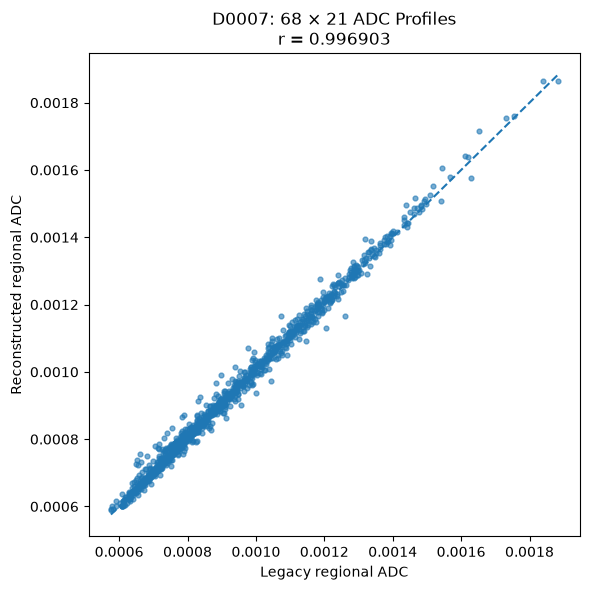

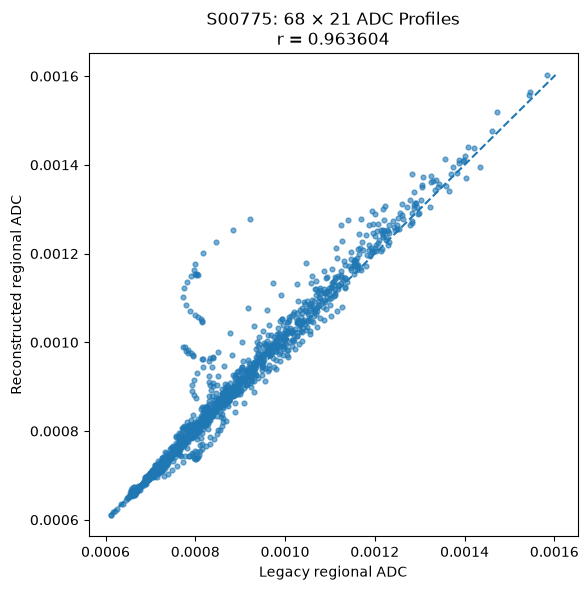

In [159]:
# ============================================================
# FINAL END-TO-END ADC PROFILE SCATTER
# ============================================================

for subject in SUBJECTS:

    old_values = END_TO_END_VALUES[
        subject
    ]["old"]

    new_values = END_TO_END_VALUES[
        subject
    ]["new"]

    correlation = np.corrcoef(
        old_values,
        new_values,
    )[0, 1]

    lower = min(
        old_values.min(),
        new_values.min(),
    )

    upper = max(
        old_values.max(),
        new_values.max(),
    )

    plt.figure(
        figsize=(6, 6)
    )

    plt.scatter(
        old_values,
        new_values,
        s=12,
        alpha=0.6,
    )

    plt.plot(
        [lower, upper],
        [lower, upper],
        linestyle="--",
    )

    plt.xlabel(
        "Legacy regional ADC"
    )

    plt.ylabel(
        "Reconstructed regional ADC"
    )

    plt.title(
        f"{subject}: 68 × 21 ADC Profiles\n"
        f"r = {correlation:.6f}"
    )

    plt.tight_layout()

    plt.show()

In [160]:
# ============================================================
# 7.5 RANK REGIONS BY DISAGREEMENT
# ============================================================

for subject in SUBJECTS:

    subject_df = (
        regional_comparison_df[
            regional_comparison_df[
                "Subject"
            ] == subject
        ]
        .copy()
    )

    subject_df = (
        subject_df
        .sort_values(
            "RMSE",
            ascending=False,
        )
        .reset_index(
            drop=True
        )
    )

    print()
    print("=" * 70)
    print(subject)
    print("TOP 10 REGIONS BY RMSE")
    print("=" * 70)

    display(
        subject_df[
            [
                "Region",
                "Correlation",
                "MAE",
                "RMSE",
                "Mean difference",
            ]
        ].head(10)
    )


D0007
TOP 10 REGIONS BY RMSE


,Region,Correlation,MAE,RMSE,Mean difference
0,rh_temporalpole,0.997006,0.000058,0.000064,0.000056
1,rh_entorhinal,0.997535,0.000057,0.000064,0.000054
2,rh_pericalcarine,0.999361,0.000039,0.000040,0.000039
3,lh_transversetemporal,0.999952,0.000022,0.000032,0.000022
4,rh_lateraloccipital,0.997808,0.000019,0.000032,-0.000012
5,rh_inferiortemporal,0.999926,0.000020,0.000030,-0.000017
6,rh_fusiform,0.997024,0.000023,0.000029,0.000017
7,lh_medialorbitofrontal,0.999853,0.000025,0.000026,0.000025
8,lh_parahippocampal,0.999412,0.000022,0.000026,0.000022
9,lh_insula,0.999435,0.000024,0.000025,0.000024



S00775
TOP 10 REGIONS BY RMSE


,Region,Correlation,MAE,RMSE,Mean difference
0,lh_entorhinal,0.648893,0.000325,0.000329,0.000325
1,rh_entorhinal,-0.044832,0.000148,0.000153,0.000148
2,lh_temporalpole,0.955503,0.000088,0.000100,0.000086
3,rh_parahippocampal,0.970586,0.000062,0.000072,0.000061
4,rh_temporalpole,0.979767,0.000050,0.000055,0.000050
5,rh_isthmuscingulate,0.999581,0.000042,0.000047,0.000042
6,rh_parsorbitalis,0.998486,0.000024,0.000043,0.000023
7,rh_lateraloccipital,0.838406,0.000035,0.000040,-0.000034
8,lh_lateraloccipital,0.938062,0.000032,0.000040,-0.000032
9,lh_cuneus,0.998347,0.000039,0.000040,-0.000039


In [ ]:
# ============================================================
# S00775:
# RELATE REGIONAL TRAJECTORY COUNT DIFFERENCE TO PROFILE ERROR
# ============================================================

subject = "S00775"


# ------------------------------------------------------------
# Build trajectory-count table from Section 6 comparison
# ------------------------------------------------------------

count_df = (
    trajectory_profile_comparison_df[
        trajectory_profile_comparison_df[
            "Subject"
        ] == subject
    ][
        [
            "Region",
            "Legacy trajectories",
            "Reconstructed trajectories",
        ]
    ]
    .copy()
)


count_df["Trajectory difference"] = (
    count_df["Reconstructed trajectories"]
    -
    count_df["Legacy trajectories"]
)


count_df["Trajectory difference (%)"] = (
    count_df["Trajectory difference"]
    /
    count_df["Legacy trajectories"]
    * 100
)


# ------------------------------------------------------------
# Add regional profile error
# ------------------------------------------------------------

error_df = (
    regional_comparison_df[
        regional_comparison_df[
            "Subject"
        ] == subject
    ][
        [
            "Region",
            "Correlation",
            "MAE",
            "RMSE",
            "Mean difference",
        ]
    ]
    .copy()
)


s00775_region_diagnostic_df = (

    count_df

    .merge(
        error_df,
        on="Region",
        how="inner",
    )

    .sort_values(
        "RMSE",
        ascending=False,
    )

    .reset_index(
        drop=True
    )
)


display(
    s00775_region_diagnostic_df.head(15)
)

,Region,Legacy trajectories,Reconstructed trajectories,Trajectory difference,Trajectory difference (%),Correlation,MAE,RMSE,Mean difference
0,lh_entorhinal,585,767,182,31.111111,0.648893,0.000325,0.000329,0.000325
1,rh_entorhinal,491,618,127,25.865580,-0.044832,0.000148,0.000153,0.000148
2,lh_temporalpole,496,502,6,1.209677,0.955503,0.000088,0.000100,0.000086
3,rh_parahippocampal,765,900,135,17.647059,0.970586,0.000062,0.000072,0.000061
4,rh_temporalpole,526,521,-5,-0.950570,0.979767,0.000050,0.000055,0.000050
5,rh_isthmuscingulate,1166,1211,45,3.859348,0.999581,0.000042,0.000047,0.000042
6,rh_parsorbitalis,949,1019,70,7.376185,0.998486,0.000024,0.000043,0.000023
7,rh_lateraloccipital,6212,6545,333,5.360592,0.838406,0.000035,0.000040,-0.000034
8,lh_lateraloccipital,6667,6808,141,2.114894,0.938062,0.000032,0.000040,-0.000032
9,lh_cuneus,2103,1990,-113,-5.373276,0.998347,0.000039,0.000040,-0.000039


## Validation of FreeSurfer Parcellation Differences

The final 68 × 21 regional ADC profiles showed high overall agreement between the historical and reproduced pipelines, but the residual error was highly concentrated in a few medial temporal regions, especially the entorhinal cortex.

To determine whether these discrepancies originated from the downstream trajectory-analysis pipeline or from upstream T1/FreeSurfer processing, the historical and reproduced FreeSurfer parcellations were compared directly.

For each Desikan-Killiany cortical region, the following quantities were compared:

1. Number of vertices assigned to the region in `aparc.annot`
2. White-surface area of the region
3. Number of cortical trajectories assigned to the region

If trajectory-count differences closely follow FreeSurfer vertex-count differences, this indicates that the downstream region-assignment step is faithfully reflecting differences already present in the FreeSurfer parcellation, rather than introducing a new error.

In [163]:
from pathlib import Path
import numpy as np
import pandas as pd

from nibabel.freesurfer.io import read_annot, read_geometry


# ============================================================
# Configuration
# ============================================================

SUBJECT = "S00775"

OLD_FS = Path(
    "/mnt/newStor/paros/paros_WORK/xintong/test/"
    "existing_pipeline/output/S00775/S00775"
)

NEW_FS = Path(
    "/mnt/newStor/paros/paros_WORK/xintong/test/"
    "new_pipeline/S00775/preprocess/freesurfer/S00775"
)

TRAJECTORY_COUNT_FILE = Path(
    "/mnt/newStor/paros/paros_WORK/xintong/test/"
    "new_pipeline/S00775/validation_error_attribution/"
    "trajectory_count_stage_comparison.csv"
)

TARGET_REGIONS = [
    "lh_entorhinal",
    "rh_entorhinal",
    "lh_parahippocampal",
    "rh_parahippocampal",
    "lh_temporalpole",
    "rh_temporalpole",
]


# ============================================================
# Helper functions
# ============================================================

def triangle_areas(vertices, faces):
    """Calculate the area of every triangular surface face."""
    a = vertices[faces[:, 0]]
    b = vertices[faces[:, 1]]
    c = vertices[faces[:, 2]]

    cross = np.cross(
        b - a,
        c - a
    )

    return 0.5 * np.linalg.norm(
        cross,
        axis=1
    )


def region_surface_areas(labels, vertices, faces):
    """
    Calculate conservative regional surface area.

    A triangular face is assigned to a region only if all
    three vertices belong to the same annotation label.
    """

    areas = triangle_areas(
        vertices,
        faces
    )

    face_labels = labels[faces]

    same_region = (
        (face_labels[:, 0] == face_labels[:, 1])
        &
        (face_labels[:, 1] == face_labels[:, 2])
    )

    output = {}

    for label_id in np.unique(labels):

        if label_id < 0:
            continue

        use = (
            same_region
            &
            (face_labels[:, 0] == label_id)
        )

        output[int(label_id)] = float(
            areas[use].sum()
        )

    return output


def load_freesurfer_regions(fs_root, hemisphere):
    """
    Load aparc annotation and white/pial surfaces for one hemisphere.
    """

    annot_file = (
        fs_root /
        "label" /
        f"{hemisphere}.aparc.annot"
    )

    white_file = (
        fs_root /
        "surf" /
        f"{hemisphere}.white"
    )

    pial_file = (
        fs_root /
        "surf" /
        f"{hemisphere}.pial"
    )

    labels, _, names = read_annot(
        str(annot_file),
        orig_ids=False
    )

    names = [
        name.decode("utf-8")
        if isinstance(name, bytes)
        else str(name)
        for name in names
    ]

    white_vertices, white_faces = read_geometry(
        str(white_file)
    )

    pial_vertices, pial_faces = read_geometry(
        str(pial_file)
    )

    white_areas = region_surface_areas(
        labels,
        white_vertices,
        white_faces
    )

    pial_areas = region_surface_areas(
        labels,
        pial_vertices,
        pial_faces
    )

    rows = []

    for idx, name in enumerate(names):

        if name in {
            "unknown",
            "corpuscallosum",
        }:
            continue

        rows.append({
            "region":
                f"{hemisphere}_{name}",

            "vertex_count":
                int(np.sum(labels == idx)),

            "white_area_mm2":
                white_areas.get(
                    idx,
                    np.nan
                ),

            "pial_area_mm2":
                pial_areas.get(
                    idx,
                    np.nan
                ),
        })

    return pd.DataFrame(rows)

In [164]:
# ============================================================
# Load historical and reproduced FreeSurfer outputs
# ============================================================

old_regions = pd.concat(
    [
        load_freesurfer_regions(
            OLD_FS,
            "lh"
        ),
        load_freesurfer_regions(
            OLD_FS,
            "rh"
        ),
    ],
    ignore_index=True
)

new_regions = pd.concat(
    [
        load_freesurfer_regions(
            NEW_FS,
            "lh"
        ),
        load_freesurfer_regions(
            NEW_FS,
            "rh"
        ),
    ],
    ignore_index=True
)


fs_compare = old_regions.merge(
    new_regions,
    on="region",
    suffixes=(
        "_old",
        "_new"
    )
)


for metric in [
    "vertex_count",
    "white_area_mm2",
    "pial_area_mm2",
]:

    fs_compare[f"{metric}_diff"] = (
        fs_compare[f"{metric}_new"]
        - fs_compare[f"{metric}_old"]
    )

    fs_compare[f"{metric}_pct_diff"] = (
        100
        * fs_compare[f"{metric}_diff"]
        / fs_compare[f"{metric}_old"]
    )


print(
    "Historical cortical regions:",
    len(old_regions)
)

print(
    "Reproduced cortical regions:",
    len(new_regions)
)

print(
    "Matched regions:",
    len(fs_compare)
)

Historical cortical regions: 68
Reproduced cortical regions: 68
Matched regions: 68


In [165]:
# ============================================================
# Examine medial temporal regions
# ============================================================

target_fs = (
    fs_compare[
        fs_compare["region"].isin(
            TARGET_REGIONS
        )
    ]
    .copy()
    .sort_values("region")
)


target_fs[
    [
        "region",

        "vertex_count_old",
        "vertex_count_new",
        "vertex_count_pct_diff",

        "white_area_mm2_old",
        "white_area_mm2_new",
        "white_area_mm2_pct_diff",

        "pial_area_mm2_old",
        "pial_area_mm2_new",
        "pial_area_mm2_pct_diff",
    ]
]

,region,vertex_count_old,vertex_count_new,vertex_count_pct_diff,white_area_mm2_old,white_area_mm2_new,white_area_mm2_pct_diff,pial_area_mm2_old,pial_area_mm2_new,pial_area_mm2_pct_diff
4,lh_entorhinal,585,767,31.111111,328.065055,380.188444,15.888126,670.084658,679.674660,1.431163
14,lh_parahippocampal,880,941,6.931818,492.958192,522.159940,5.923778,678.063920,714.197874,5.328989
31,lh_temporalpole,496,522,5.241935,415.674887,359.905229,-13.416653,821.977305,701.746535,-14.627018
38,rh_entorhinal,491,618,25.865580,281.146843,313.626022,11.552390,563.897993,605.152745,7.315996
48,rh_parahippocampal,765,900,17.647059,454.877205,502.661687,10.504919,645.645487,728.121534,12.774200
65,rh_temporalpole,537,536,-0.186220,389.663395,400.884355,2.879655,742.493345,646.224970,-12.965554


Historical and reproduced regional profiles showed high overall agreement, with residual discrepancies concentrated in a small number of medial temporal regions. These differences were strongly associated with FreeSurfer parcellation differences; regional vertex-count changes were almost perfectly correlated with trajectory-count changes (r≈0.996), indicating that the remaining profile differences originated primarily from upstream cortical reconstruction/parcellation rather than the downstream trajectory sampling pipeline.

In [167]:
# ============================================================
# Compare FreeSurfer region size with trajectory assignment
# ============================================================

trajectory_counts = pd.read_csv(
    TRAJECTORY_COUNT_FILE
)


fs_traj_compare = fs_compare.merge(
    trajectory_counts[
        [
            "region",
            "old_region_count",
            "new_region_count",
            "region_count_pct_diff",
        ]
    ],
    on="region",
    how="inner"
)


r_vertex_vs_trajectory = np.corrcoef(
    fs_traj_compare[
        "vertex_count_pct_diff"
    ],
    fs_traj_compare[
        "region_count_pct_diff"
    ],
)[0, 1]


r_area_vs_trajectory = np.corrcoef(
    fs_traj_compare[
        "white_area_mm2_pct_diff"
    ],
    fs_traj_compare[
        "region_count_pct_diff"
    ],
)[0, 1]


print(
    "Correlation between FreeSurfer vertex-count "
    "difference and trajectory-count difference:"
)

print(
    f"r = {r_vertex_vs_trajectory:.6f}"
)


print()

print(
    "Correlation between FreeSurfer white-surface "
    "area difference and trajectory-count difference:"
)

print(
    f"r = {r_area_vs_trajectory:.6f}"
)
# ============================================================
# Target regions: FreeSurfer vs trajectory assignment
# ============================================================

fs_traj_compare[
    fs_traj_compare["region"].isin(
        TARGET_REGIONS
    )
][
    [
        "region",

        "vertex_count_old",
        "vertex_count_new",
        "vertex_count_pct_diff",

        "old_region_count",
        "new_region_count",
        "region_count_pct_diff",

        "white_area_mm2_pct_diff",
    ]
].sort_values(
    "region"
)

Correlation between FreeSurfer vertex-count difference and trajectory-count difference:
r = 0.995933

Correlation between FreeSurfer white-surface area difference and trajectory-count difference:
r = 0.671365


,region,vertex_count_old,vertex_count_new,vertex_count_pct_diff,old_region_count,new_region_count,region_count_pct_diff,white_area_mm2_pct_diff
4,lh_entorhinal,585,767,31.111111,585.0,767.0,31.111111,15.888126
14,lh_parahippocampal,880,941,6.931818,880.0,941.0,6.931818,5.923778
31,lh_temporalpole,496,522,5.241935,496.0,502.0,1.209677,-13.416653
38,rh_entorhinal,491,618,25.865580,491.0,618.0,25.865580,11.552390
48,rh_parahippocampal,765,900,17.647059,765.0,900.0,17.647059,10.504919
65,rh_temporalpole,537,536,-0.186220,526.0,521.0,-0.950570,2.879655
